# Emotion recognition from scratch - JarvisTEC (`emotion_cnn`)

**Team members:** Anthony Jafeth Arias Robleto (2020007243), Randy Espinoza Downing (2021031263), Kenneth Jhoan Araya Arguedas (2024177221)
**Dataset:** [FER-2013 (Kaggle, msambare/fer2013)](https://www.kaggle.com/datasets/msambare/fer2013), the facial expression dataset of the ICML 2013 representation learning challenge (Goodfellow et al., 2013).

A convolutional neural network trained **from random initialization** on FER-2013 to classify the expression of a face into 7 emotions. It is the project's own alternative to the pretrained networks (FER+ and HSEmotion) that the backend also offers. The face is located by the pretrained YuNet detector in the backend; this notebook trains only the expression classifier.

| Section | Points |
|---|---|
| 1. Problem analysis | 0.5 |
| 2. Data understanding | 0.5 |
| 3. Data exploration | 0.5 |
| 4. Model | 2 |
| 5. Evaluation | 1 |
| 6. Conclusion | 0.5 |

## Configuration

In [1]:
import json
import random
import time
import warnings
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import display
from sklearn import metrics
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore")

MODEL_NAME = "emotion_cnn"
# Kaggle layout: train/<emotion>/*.jpg and test/<emotion>/*.jpg
DATA_DIR = Path("../../data/fer2013")
ARTIFACTS = Path("../../artifacts")
# One JSON line per epoch, to follow the training while it runs
# (data/ is git-ignored).
PROGRESS = Path("../../data/training_progress") / f"{MODEL_NAME}.jsonl"
# Folder name -> emotion name used by the API.
FOLDERS = {
    "angry": "anger",
    "disgust": "disgust",
    "fear": "fear",
    "happy": "happiness",
    "neutral": "neutral",
    "sad": "sadness",
    "surprise": "surprise",
}
CLASSES = list(FOLDERS.values())
IMAGE_SIZE = 48
VALIDATION_SHARE = 0.1
EPOCHS = 60
BATCH_SIZE = 128
LEARNING_RATE = 3e-3
WEIGHT_DECAY = 5e-4
LABEL_SMOOTHING = 0.1
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch", torch.__version__, "on", DEVICE,
      torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")

PyTorch 2.14.1+cu130 on cuda NVIDIA GeForce RTX 5060


## 1. Problem analysis

JarvisTEC adapts the tone of its answers to the user's mood, read from the webcam. The task is to estimate the **dominant emotion of a face**: anger, disgust, fear, happiness, neutral, sadness or surprise.

- **Task type:** multiclass image classification (7 classes). The input is a cropped grayscale face of 48x48 pixels, the format of FER-2013; in the application, the face detector of the backend produces the crop from the camera frame.
- **Why a convolutional network:** the expression is a spatial pattern (mouth corners, eyebrows, eyes) that convolutional networks learn directly from pixels (LeCun et al., 1998); on FER-2013, small VGG-style networks trained from scratch reach roughly 65-73 % accuracy (Khaireddin & Chen, 2021), while human accuracy on this dataset is about 65 % (Goodfellow et al., 2013).
- **Success metrics:** **accuracy** (the standard metric of FER-2013, which makes the result comparable with the literature) and **macro F1**, because the classes are imbalanced (disgust is rare) and accuracy alone would hide a class that is never recognized.
- **Baselines:** the most frequent class, and a classical pipeline (principal component analysis of the pixels + logistic regression, in the spirit of eigenfaces) that shows what a linear model achieves without deep learning.

## 2. Data understanding

In [2]:
def load_split(split):
    images, labels = [], []
    for folder, emotion in FOLDERS.items():
        for path in sorted((DATA_DIR / split / folder).glob("*.jpg")):
            images.append(cv2.imread(str(path), cv2.IMREAD_GRAYSCALE))
            labels.append(CLASSES.index(emotion))
    return np.stack(images), np.array(labels)


X_all, y_all = load_split("train")
X_test, y_test = load_split("test")
print("Train images:", X_all.shape, X_all.dtype)
print("Test images: ", X_test.shape)
counts = pd.DataFrame({
    "train": np.bincount(y_all, minlength=len(CLASSES)),
    "test": np.bincount(y_test, minlength=len(CLASSES)),
}, index=CLASSES)
counts["% train"] = (counts["train"] / counts["train"].sum() * 100).round(1)
display(counts)

Train images: (28709, 48, 48) uint8
Test images:  (7178, 48, 48)


,train,test,% train
anger,3995,958,13.9
disgust,436,111,1.5
fear,4097,1024,14.3
happiness,7215,1774,25.1
neutral,4965,1233,17.3
sadness,4830,1247,16.8
surprise,3171,831,11.0


In [3]:
# Exact duplicates: the same picture can appear more than once.
hashes_train = pd.Series([hash(x.tobytes()) for x in X_all])
hashes_test = pd.Series([hash(x.tobytes()) for x in X_test])
print("Duplicated images inside train:", hashes_train.duplicated().sum())
print("Test images also present in train:", hashes_test.isin(set(hashes_train)).sum())
blank = (X_all.std(axis=(1, 2)) < 2).sum()
print("Almost uniform images (no face) in train:", blank)

Duplicated images inside train: 1236
Test images also present in train: 568


Almost uniform images (no face) in train: 12


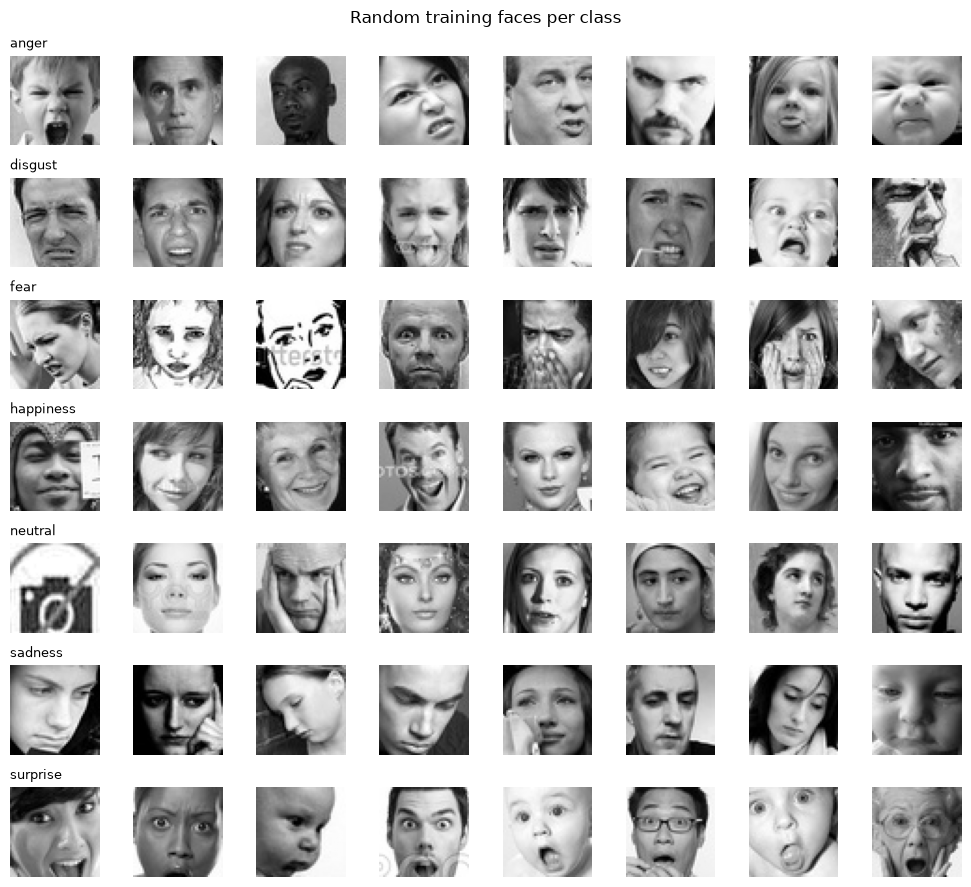

In [4]:
fig, axes = plt.subplots(len(CLASSES), 8, figsize=(10, 9))
rng = np.random.default_rng(SEED)
for row, emotion in enumerate(CLASSES):
    picks = rng.choice(np.flatnonzero(y_all == row), 8, replace=False)
    for col, index in enumerate(picks):
        axes[row, col].imshow(X_all[index], cmap="gray")
        axes[row, col].axis("off")
    axes[row, 0].set_title(emotion, loc="left", fontsize=9)
plt.suptitle("Random training faces per class")
plt.tight_layout()
plt.show()

FER-2013 contains 35 887 grayscale faces of 48x48 pixels collected from web image searches, already aligned and cropped, each labeled with one of 7 emotions. The Kaggle version is split into 28 709 training and 7 178 test images (the original public and private test sets together). The images vary in pose, lighting, age and occlusion (hands, glasses, watermarks), and some are drawings or are not faces at all. The labels are known to be noisy: Barsoum et al. (2016) relabeled the dataset with 10 annotators per image (FER+) and found frequent disagreement. The output above shows how many images are exact duplicates and how many are almost uniform; they are few and are kept, as in the literature, so the result stays comparable.

## 3. Data exploration

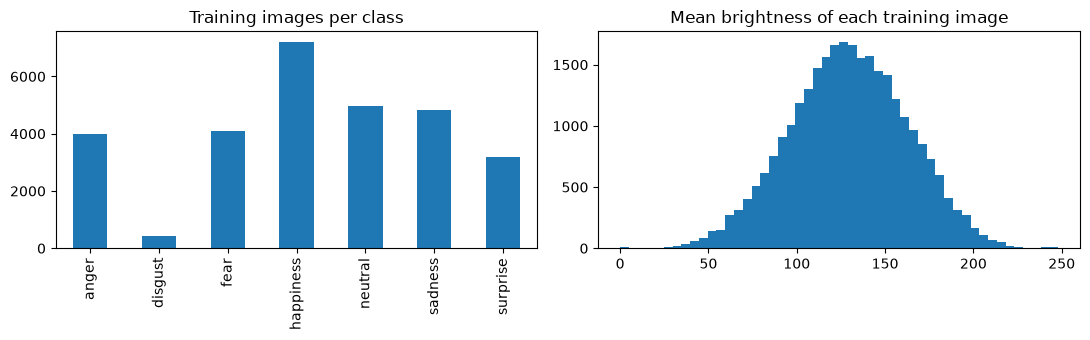

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
counts["train"].plot(kind="bar", ax=axes[0], title="Training images per class")
axes[1].hist(X_all.mean(axis=(1, 2)), bins=50)
axes[1].set_title("Mean brightness of each training image")
plt.tight_layout()
plt.show()

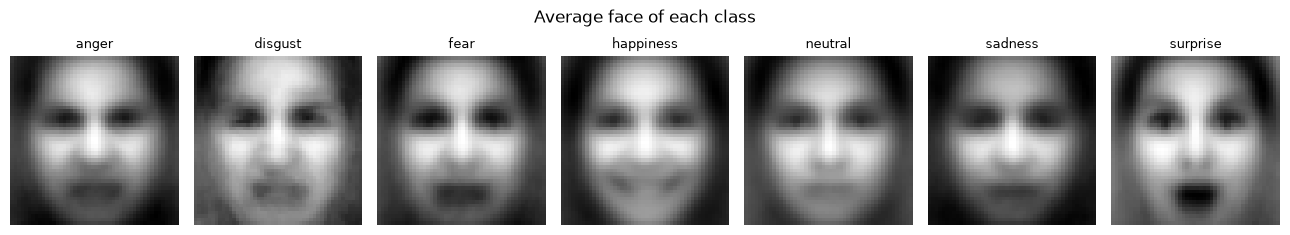

In [6]:
fig, axes = plt.subplots(1, len(CLASSES), figsize=(13, 2.4))
for index, emotion in enumerate(CLASSES):
    axes[index].imshow(X_all[y_all == index].mean(axis=0), cmap="gray")
    axes[index].set_title(emotion, fontsize=9)
    axes[index].axis("off")
plt.suptitle("Average face of each class")
plt.tight_layout()
plt.show()

- **Imbalance:** happiness is the largest class (about 25 % of the training set) and disgust the smallest (about 1.5 %, 436 images). A network trained without correction would almost never predict disgust, so the loss is **weighted by the inverse class frequency**.
- **Average faces:** even the per-class averages show the expected features (an open smiling mouth for happiness, an open mouth and raised eyebrows for surprise), so the signal is in the spatial arrangement of the face, which supports a convolutional model.
- **Brightness:** it varies widely between images, so each image is scaled to 0-1 and the training applies random brightness and contrast changes, which also helps with the webcam lighting of the application.
- **Pose and position:** faces are not perfectly centered, so training uses random crops, small rotations and horizontal flips (an expression is symmetric enough for a flip to keep its label).

## 4. Model

The training set is split into **train (90 %)** and **validation (10 %)**, stratified by class. The validation set selects the best epoch; the test set is used once, in section 5.

In [7]:
X_train, X_val, y_train, y_val = train_test_split(
    X_all, y_all, test_size=VALIDATION_SHARE, stratify=y_all, random_state=SEED
)
print("train", X_train.shape[0], "| validation", X_val.shape[0], "| test", X_test.shape[0])

train 25838 | validation 2871 | test 7178


### Baselines

1. **Most frequent class.**
2. **PCA + logistic regression:** the pixels are projected on their 150 principal components ("eigenfaces", Turk & Pentland, 1991) and a linear classifier is trained on them; a classical, non-deep approach.

In [8]:
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


def pixel_features(images):
    return images.reshape(len(images), -1).astype(np.float32) / 255


H_train, H_val = pixel_features(X_train), pixel_features(X_val)
majority = np.bincount(y_train).argmax()
start = time.time()
hog_model = make_pipeline(
    StandardScaler(), PCA(150, random_state=SEED),
    LogisticRegression(max_iter=2000, C=0.1, class_weight="balanced"),
)
hog_model.fit(H_train, y_train)
val_hog = hog_model.predict(H_val)
baselines = pd.DataFrame([
    {"model": "Most frequent class",
     "val accuracy": metrics.accuracy_score(y_val, np.full_like(y_val, majority)),
     "val macro F1": metrics.f1_score(y_val, np.full_like(y_val, majority), average="macro")},
    {"model": "PCA + logistic regression",
     "val accuracy": metrics.accuracy_score(y_val, val_hog),
     "val macro F1": metrics.f1_score(y_val, val_hog, average="macro")},
]).round(4)
print(f"{H_train.shape[1]} pixels per image -> 150 components, fitted in {time.time() - start:.0f} s")
display(baselines)

2304 pixels per image -> 150 components, fitted in 4 s


,model,val accuracy,val macro F1
0,Most frequent class,0.2515,0.0574
1,PCA + logistic regression,0.3191,0.2814


### Convolutional network

A VGG-style network (Simonyan & Zisserman, 2015) sized for 48x48 inputs, with batch normalization (Ioffe & Szegedy, 2015) and dropout (Srivastava et al., 2014):

- 4 blocks of two 3x3 convolutions (64, 128, 256 and 512 filters), each followed by batch normalization and ReLU, then 2x2 max pooling and dropout.
- Global average pooling, a 256-unit dense layer with dropout, and 7 outputs.
- All weights start at random (PyTorch's default Kaiming initialization): **no pretrained weights are used**.

Training: AdamW (Loshchilov & Hutter, 2019) with a one-cycle learning rate schedule (Smith & Topin, 2019), cross-entropy weighted by inverse class frequency, label smoothing 0.1 (it softens the noisy labels) and data augmentation computed on the GPU: random shifts of up to 4 pixels, rotations of up to 10 degrees, scaling of 0.9-1.1, horizontal flips, brightness and contrast changes. The epoch with the best validation macro F1 is kept.

In [9]:
class EmotionCNN(nn.Module):
    def __init__(self, classes=len(CLASSES), widths=(64, 128, 256, 512), dropout=0.25):
        super().__init__()
        layers, channels = [], 1
        for width in widths:
            layers += [
                nn.Conv2d(channels, width, 3, padding=1, bias=False),
                nn.BatchNorm2d(width), nn.ReLU(inplace=True),
                nn.Conv2d(width, width, 3, padding=1, bias=False),
                nn.BatchNorm2d(width), nn.ReLU(inplace=True),
                nn.MaxPool2d(2), nn.Dropout(dropout),
            ]
            channels = width
        self.features = nn.Sequential(*layers)
        self.head = nn.Sequential(
            nn.Flatten(), nn.Linear(channels, 256), nn.ReLU(inplace=True),
            nn.Dropout(0.5), nn.Linear(256, classes),
        )

    def forward(self, x):
        x = self.features(x)
        # Global average pooling; written as a mean so the exported ONNX
        # graph stays simple for OpenCV.
        x = x.mean(dim=(2, 3), keepdim=True)
        return self.head(x)


model = EmotionCNN().to(DEVICE)
parameters = sum(p.numel() for p in model.parameters())
print(f"{parameters:,} trainable parameters, all randomly initialized")

4,819,271 trainable parameters, all randomly initialized


In [10]:
def to_tensor(images):
    # uint8 0-255 -> float 0-1, shape (N, 1, 48, 48)
    return torch.from_numpy(images).float().div(255).unsqueeze(1)


T_train, T_val, T_test = to_tensor(X_train), to_tensor(X_val), to_tensor(X_test)
Y_train = torch.from_numpy(y_train).long()


def augment(batch):
    n = batch.shape[0]
    angle = (torch.rand(n, device=batch.device) - 0.5) * 2 * np.deg2rad(10)
    scale = 1 + (torch.rand(n, device=batch.device) - 0.5) * 0.2
    shift = (torch.rand(n, 2, device=batch.device) - 0.5) * 2 * (4 / 24)
    flip = torch.where(torch.rand(n, device=batch.device) < 0.5, -1.0, 1.0)
    cos, sin = torch.cos(angle) / scale, torch.sin(angle) / scale
    theta = torch.stack([
        torch.stack([cos * flip, -sin, shift[:, 0]], dim=1),
        torch.stack([sin * flip, cos, shift[:, 1]], dim=1),
    ], dim=1)
    grid = F.affine_grid(theta, batch.shape, align_corners=False)
    batch = F.grid_sample(batch, grid, padding_mode="border", align_corners=False)
    contrast = 1 + (torch.rand(n, 1, 1, 1, device=batch.device) - 0.5) * 0.6
    brightness = (torch.rand(n, 1, 1, 1, device=batch.device) - 0.5) * 0.3
    mean = batch.mean(dim=(2, 3), keepdim=True)
    return ((batch - mean) * contrast + mean + brightness).clamp(0, 1)


@torch.no_grad()
def predict_proba(net, images, batch_size=512):
    net.eval()
    outputs = []
    for start in range(0, len(images), batch_size):
        batch = images[start:start + batch_size].to(DEVICE)
        outputs.append(F.softmax(net(batch), dim=1).cpu())
    return torch.cat(outputs).numpy()


frequency = np.bincount(y_train, minlength=len(CLASSES))
class_weights = torch.tensor(len(y_train) / (len(CLASSES) * frequency), dtype=torch.float32)
print("Class weights:", dict(zip(CLASSES, class_weights.numpy().round(2))))

Class weights: {'anger': np.float32(1.03), 'disgust': np.float32(9.42), 'fear': np.float32(1.0), 'happiness': np.float32(0.57), 'neutral': np.float32(0.83), 'sadness': np.float32(0.85), 'surprise': np.float32(1.29)}


In [11]:
criterion = nn.CrossEntropyLoss(weight=class_weights.to(DEVICE), label_smoothing=LABEL_SMOOTHING)
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
steps_per_epoch = int(np.ceil(len(T_train) / BATCH_SIZE))
scheduler = torch.optim.lr_scheduler.OneCycleLR(
    optimizer, max_lr=LEARNING_RATE, epochs=EPOCHS, steps_per_epoch=steps_per_epoch
)
generator = torch.Generator().manual_seed(SEED)
PROGRESS.parent.mkdir(parents=True, exist_ok=True)
PROGRESS.write_text(json.dumps({"model": MODEL_NAME, "epochs": EPOCHS}) + "\n")
history, best_f1, best_state = [], -1.0, None
start = time.time()
for epoch in range(1, EPOCHS + 1):
    model.train()
    order = torch.randperm(len(T_train), generator=generator)
    total_loss = 0.0
    for begin in range(0, len(order), BATCH_SIZE):
        index = order[begin:begin + BATCH_SIZE]
        batch = augment(T_train[index].to(DEVICE))
        loss = criterion(model(batch), Y_train[index].to(DEVICE))
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        scheduler.step()
        total_loss += loss.item() * len(index)
    val_pred = predict_proba(model, T_val).argmax(axis=1)
    val_acc = metrics.accuracy_score(y_val, val_pred)
    val_f1 = metrics.f1_score(y_val, val_pred, average="macro")
    history.append({"epoch": epoch, "train loss": total_loss / len(T_train),
                    "val accuracy": val_acc, "val macro F1": val_f1})
    if val_f1 > best_f1:
        best_f1, best_epoch = val_f1, epoch
        best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
    with PROGRESS.open("a") as log:
        log.write(json.dumps({**history[-1], "seconds": round(time.time() - start, 1)}) + "\n")
    if epoch % 5 == 0 or epoch == 1:
        print(f"epoch {epoch:3d}  loss {history[-1]['train loss']:.3f}  "
              f"val acc {val_acc:.4f}  val F1 {val_f1:.4f}  ({time.time() - start:.0f} s)")
model.load_state_dict(best_state)
print(f"Best epoch: {best_epoch} (validation macro F1 {best_f1:.4f})")

epoch   1  loss 2.131  val acc 0.0244  val F1 0.0182  (27 s)


epoch   5  loss 1.795  val acc 0.4646  val F1 0.3804  (63 s)


epoch  10  loss 1.684  val acc 0.4295  val F1 0.3893  (106 s)


epoch  15  loss 1.616  val acc 0.5354  val F1 0.4376  (150 s)


epoch  20  loss 1.530  val acc 0.6047  val F1 0.5334  (193 s)


...

epoch  40  loss 1.308  val acc 0.6639  val F1 0.6165  (369 s)


epoch  45  loss 1.244  val acc 0.6844  val F1 0.6444  (412 s)


epoch  50  loss 1.194  val acc 0.6897  val F1 0.6608  (456 s)


epoch  55  loss 1.168  val acc 0.6921  val F1 0.6624  (500 s)


epoch  60  loss 1.163  val acc 0.6931  val F1 0.6618  (544 s)
Best epoch: 56 (validation macro F1 0.6658)


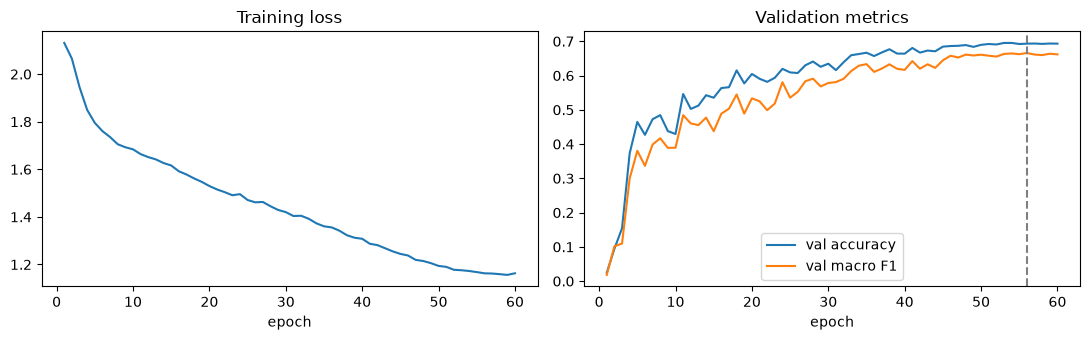

,model,val accuracy,val macro F1
0,Most frequent class,0.2515,0.0574
1,PCA + logistic regression,0.3191,0.2814
2,CNN from scratch,0.6931,0.6658


In [12]:
curves = pd.DataFrame(history).set_index("epoch")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
curves["train loss"].plot(ax=axes[0], title="Training loss")
curves[["val accuracy", "val macro F1"]].plot(ax=axes[1], title="Validation metrics")
axes[1].axvline(best_epoch, color="gray", linestyle="--")
plt.tight_layout()
plt.show()
val_cnn = predict_proba(model, T_val).argmax(axis=1)
comparison = pd.concat([baselines, pd.DataFrame([{
    "model": "CNN from scratch",
    "val accuracy": metrics.accuracy_score(y_val, val_cnn),
    "val macro F1": metrics.f1_score(y_val, val_cnn, average="macro"),
}]).round(4)], ignore_index=True)
display(comparison)

The model is chosen on the validation set: the network is compared with the two baselines above before looking at the test set.

## 5. Evaluation

The chosen network is evaluated **once** on the 7 178 test images, which were never used for training or for choosing the epoch. The two baselines are evaluated on the same images. For reference, the two **pretrained** networks that the backend also offers are run on the same test set: FER+ was trained on the relabeled FER-2013 training images, so its comparison is fair; HSEmotion was trained on AffectNet (larger color photos), so FER-2013 is outside its domain.

In [13]:
test_proba = predict_proba(model, T_test)
test_pred = test_proba.argmax(axis=1)
test_metrics = {
    "accuracy": metrics.accuracy_score(y_test, test_pred),
    "f1_macro": metrics.f1_score(y_test, test_pred, average="macro"),
    "precision_macro": metrics.precision_score(y_test, test_pred, average="macro"),
    "recall_macro": metrics.recall_score(y_test, test_pred, average="macro"),
}
print(metrics.classification_report(y_test, test_pred, target_names=CLASSES, digits=3))
test_hog = hog_model.predict(pixel_features(X_test))
rows = [
    {"model": "Most frequent class",
     "accuracy": metrics.accuracy_score(y_test, np.full_like(y_test, majority)),
     "macro F1": metrics.f1_score(y_test, np.full_like(y_test, majority), average="macro")},
    {"model": "PCA + logistic regression",
     "accuracy": metrics.accuracy_score(y_test, test_hog),
     "macro F1": metrics.f1_score(y_test, test_hog, average="macro")},
    {"model": "CNN from scratch (ours)",
     "accuracy": test_metrics["accuracy"], "macro F1": test_metrics["f1_macro"]},
]

              precision    recall  f1-score   support

       anger      0.609     0.641     0.625       958
     disgust      0.497     0.721     0.588       111
        fear      0.578     0.497     0.535      1024
   happiness      0.905     0.851     0.877      1774
     neutral      0.584     0.728     0.648      1233
     sadness      0.615     0.496     0.549      1247
    surprise      0.759     0.838     0.796       831

    accuracy                          0.686      7178
   macro avg      0.650     0.682     0.660      7178
weighted avg      0.690     0.686     0.684      7178



In [14]:
# Pretrained references, through OpenCV as in the backend.
FERPLUS_ORDER = ["neutral", "happiness", "surprise", "sadness", "anger", "disgust", "fear", "contempt"]
HSEMOTION_ORDER = ["anger", "contempt", "disgust", "fear", "happiness", "neutral", "sadness", "surprise"]


def run_reference(path, size, prepare, order):
    if not path.exists():
        return None
    net = cv2.dnn.readNetFromONNX(str(path))
    predictions = []
    for image in X_test:
        net.setInput(prepare(cv2.resize(image, (size, size))))
        scores = dict(zip(order, net.forward().ravel()))
        predictions.append(CLASSES.index(max(CLASSES, key=lambda c: scores[c])))
    return np.array(predictions)


mean = np.array([0.485, 0.456, 0.406], np.float32)
std = np.array([0.229, 0.224, 0.225], np.float32)
references = {
    "FER+ (pretrained)": run_reference(
        ARTIFACTS / "emotion-ferplus-8.onnx", 64,
        lambda x: x.astype(np.float32)[None, None], FERPLUS_ORDER),
    "HSEmotion (pretrained, other domain)": run_reference(
        ARTIFACTS / "enet_b0_8_best_afew.onnx", 224,
        lambda x: ((np.repeat(x[..., None], 3, 2) / 255 - mean) / std).astype(np.float32).transpose(2, 0, 1)[None],
        HSEMOTION_ORDER),
}
for name, predictions in references.items():
    if predictions is not None:
        rows.append({"model": name,
                     "accuracy": metrics.accuracy_score(y_test, predictions),
                     "macro F1": metrics.f1_score(y_test, predictions, average="macro")})
test_table = pd.DataFrame(rows).round(4)
display(test_table)

,model,accuracy,macro F1
0,Most frequent class,0.2471,0.0566
1,PCA + logistic regression,0.3348,0.2970
2,CNN from scratch (ours),0.6861,0.6598
3,FER+ (pretrained),0.5646,0.4667
4,"HSEmotion (pretrained, other domain)",0.5599,0.5066


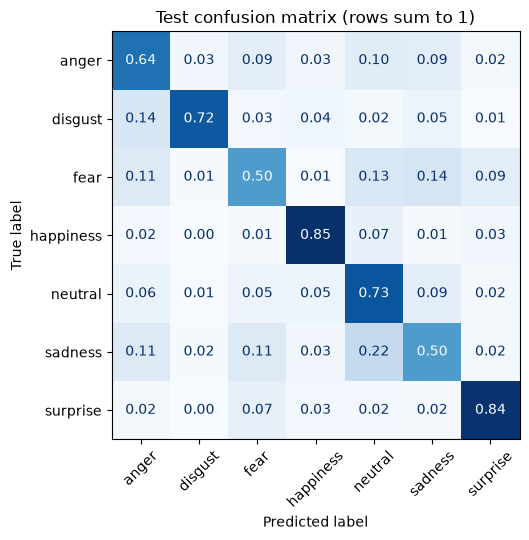

In [15]:
matrix = metrics.confusion_matrix(y_test, test_pred, normalize="true")
fig, ax = plt.subplots(figsize=(6.5, 5.5))
metrics.ConfusionMatrixDisplay(matrix, display_labels=CLASSES).plot(
    ax=ax, values_format=".2f", cmap="Blues", colorbar=False)
ax.set_title("Test confusion matrix (rows sum to 1)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

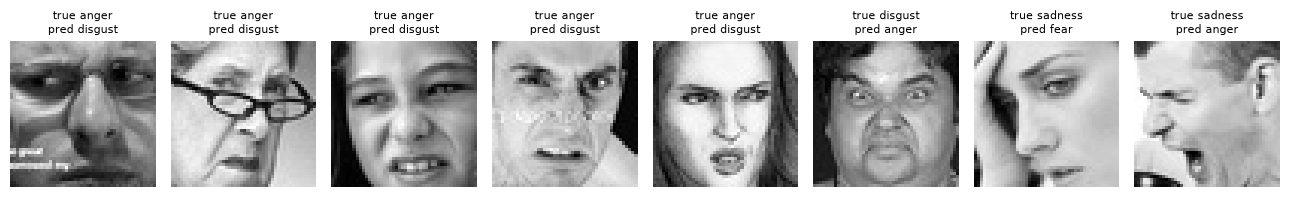

In [16]:
# Most confident mistakes: often doubtful labels.
wrong = np.flatnonzero(test_pred != y_test)
worst = wrong[np.argsort(-test_proba[wrong].max(axis=1))][:8]
fig, axes = plt.subplots(1, 8, figsize=(13, 2.4))
for ax, index in zip(axes, worst):
    ax.imshow(X_test[index], cmap="gray")
    ax.set_title(f"true {CLASSES[y_test[index]]}\npred {CLASSES[test_pred[index]]}", fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.show()

## Export for the backend

In [17]:
model.eval().cpu()
example = torch.zeros(1, 1, IMAGE_SIZE, IMAGE_SIZE)
onnx_path = ARTIFACTS / f"{MODEL_NAME}.onnx"
torch.onnx.export(model, example, onnx_path, input_names=["face"],
                  output_names=["logits"], dynamo=False, opset_version=13)

# Check that OpenCV (what the backend uses) gives the same answers as PyTorch.
net = cv2.dnn.readNetFromONNX(str(onnx_path))
sample = T_test[:64]
with torch.no_grad():
    expected = model(sample).numpy()
got = []
for image in sample.numpy():
    net.setInput(image[None])
    got.append(net.forward().ravel())
difference = np.abs(np.array(got) - expected).max()
print(f"Largest difference PyTorch vs OpenCV: {difference:.2e}")
assert difference < 1e-3

meta = {
    "model": "EmotionCNN (VGG-style, trained from scratch)",
    "dataset": "FER-2013 (Kaggle msambare/fer2013)",
    "classes": CLASSES,
    "input": {"size": IMAGE_SIZE, "channels": "grayscale", "scale": "pixel / 255"},
    "parameters": parameters,
    "hyperparameters": {
        "epochs": EPOCHS, "best_epoch": best_epoch, "batch_size": BATCH_SIZE,
        "learning_rate": LEARNING_RATE, "weight_decay": WEIGHT_DECAY,
        "label_smoothing": LABEL_SMOOTHING, "optimizer": "AdamW + OneCycleLR",
        "class_weights": "inverse frequency", "seed": SEED,
    },
    "validation_macro_f1": round(best_f1, 4),
    "test_metrics": {k: round(float(v), 4) for k, v in test_metrics.items()},
    "test_comparison": test_table.to_dict(orient="records"),
    "torch_version": torch.__version__,
}
(ARTIFACTS / f"{MODEL_NAME}.meta.json").write_text(json.dumps(meta, indent=2))
print(f"Saved {onnx_path.name} ({onnx_path.stat().st_size / 1e6:.1f} MB) and {MODEL_NAME}.meta.json")

Largest difference PyTorch vs OpenCV: 2.32e-06
Saved emotion_cnn.onnx (19.3 MB) and emotion_cnn.meta.json


## 6. Conclusion

The convolutional network trained from scratch classifies the 7 emotions of FER-2013 with a **test accuracy of 0.686 and a macro F1 of 0.660**, far above the most frequent class (0.247 / 0.057) and the classical PCA + logistic regression pipeline (0.335 / 0.297). The result is within the range reported for VGG-style networks trained from scratch on this dataset (about 0.65-0.73) and above the estimated human accuracy (about 0.65). On the same test images it also beats the two pretrained networks the backend uses by default: FER+ (0.565 / 0.467) and HSEmotion (0.560 / 0.507, trained on another dataset). Happiness (F1 0.88) and surprise (0.80) are recognized best; fear (0.54) and sadness (0.55) are confused with each other and with neutral, the usual pattern on FER-2013. The class weights make disgust, with only 436 training images, reach a recall of 0.72.

**In the application.** The backend crops the face found by YuNet, not the FER-2013 crop. To check that the result survives this change, `scripts/evaluate_emotion_pipeline.py` pastes 420 test faces into a webcam-sized frame and runs the whole pipeline: our network reaches 0.643 accuracy, against 0.561 for the average of FER+ and HSEmotion. Our network reads the central 85 % of the detector's box, the share that worked best on validation faces (not on the test set).

**Limitations:**
- FER-2013 labels are noisy (one annotator per image), and 568 test images are exact copies of training images, a known issue of the dataset that slightly flatters any model trained on it.
- The faces are grayscale, low-resolution web photos, mostly frontal and posed; real webcam faces, lighting and spontaneous expressions differ, so the accuracy in daily use will be lower.
- The face detector (YuNet) is pretrained; only the expression classifier was trained here.
- An expression is not a feeling: the model reads the face, not the mood, and it must not be used for decisions about people.

**Future improvements:** train on FER+ labels (10 annotators per image), add a second dataset with webcam conditions, and test with a few minutes of labeled frames from our own cameras.

### References
- Goodfellow, I. J., et al. (2013). Challenges in representation learning: A report on three machine learning contests. ICONIP 2013.
- LeCun, Y., Bottou, L., Bengio, Y., & Haffner, P. (1998). Gradient-based learning applied to document recognition. Proceedings of the IEEE, 86(11).
- Simonyan, K., & Zisserman, A. (2015). Very deep convolutional networks for large-scale image recognition. ICLR 2015.
- Ioffe, S., & Szegedy, C. (2015). Batch normalization. ICML 2015.
- Srivastava, N., et al. (2014). Dropout: A simple way to prevent neural networks from overfitting. JMLR, 15.
- Loshchilov, I., & Hutter, F. (2019). Decoupled weight decay regularization. ICLR 2019.
- Smith, L. N., & Topin, N. (2019). Super-convergence: Very fast training of neural networks using large learning rates. SPIE 11006.
- Khaireddin, Y., & Chen, Z. (2021). Facial emotion recognition: State of the art performance on FER2013. arXiv:2105.03588.
- Barsoum, E., Zhang, C., Ferrer, C. C., & Zhang, Z. (2016). Training deep networks for facial expression recognition with crowd-sourced label distribution. ICMI 2016.
- Turk, M., & Pentland, A. (1991). Eigenfaces for recognition. Journal of Cognitive Neuroscience, 3(1).